# Fase 2 por dentro: BPE paso a paso

Este notebook reconstruye el tokenizer de `leon/tokenizer.py` con un corpus de juguete y luego lo entrena de verdad en el Quijote:

1. Texto → bytes UTF-8.
2. Pre-tokenización con regex.
3. BPE a mano: contar pares y fusionar.
4. Encode de una palabra nueva, merge a merge.
5. Cómo crece la compresión con el número de merges.
6. Tokens especiales.
7. De loss por token a bits por byte.
8. Tokens en disco con `np.memmap`.

Requisito: `data/quijote/input.txt`. Si ya existe `data/tokenizer/leon_bpe.json` (de `train_tokenizer.py`), la última sección lo usa. Todo corre en CPU en menos de un minuto.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Works whether the kernel starts in the repo root or in the phase folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())

import re
from collections import Counter

import numpy as np

from leon.tokenizer import PRETOKENIZE_PATTERN, BPETokenizer, count_chunks, merge_pair

## 1. Texto → bytes

BPE no trabaja con caracteres sino con **bytes UTF-8**. Las letras ASCII ocupan 1 byte; `ñ`, `á` y `¿`, 2; `€`, 3; un emoji, 4. Como el vocabulario de partida son los 256 bytes posibles, **cualquier texto** tiene representación.

In [2]:
for s in ["a", "ñ", "¿", "€", "🐉"]:
    b = s.encode("utf-8")
    print(f"{s!r:6} -> {list(b)}  ({len(b)} byte{'s' if len(b) > 1 else ''})")

quijote = (ROOT / "data" / "quijote" / "input.txt").read_text(encoding="utf-8")
print(f"\nQuijote: {len(quijote):,} caracteres = {len(quijote.encode('utf-8')):,} bytes")

'a'    -> [97]  (1 byte)
'ñ'    -> [195, 177]  (2 bytes)
'¿'    -> [194, 191]  (2 bytes)
'€'    -> [226, 130, 172]  (3 bytes)
'🐉'    -> [240, 159, 144, 137]  (4 bytes)

Quijote: 2,110,705 caracteres = 2,168,288 bytes


## 2. Pre-tokenización

Antes de BPE, una regex parte el texto en trozos. Los merges nunca cruzan sus límites, así que nunca habrá un token `"a, d"`. Fíjate en tres cosas:

- El espacio va **pegado al principio** de la palabra (`' lugar'`).
- Los números se cortan en grupos de hasta 3 dígitos.
- `¿` se lleva el espacio y deja `Cuánto` sin él.

In [3]:
sample = "¿Cuánto es 1234 * 5678? En un lugar de la Mancha,  dijo."
chunks = re.findall(PRETOKENIZE_PATTERN, sample)
print(chunks)
print("¿sin pérdidas?", "".join(chunks) == sample)

['¿', 'Cuánto', ' es', ' 123', '4', ' *', ' 567', '8', '?', ' En', ' un', ' lugar', ' de', ' la', ' Mancha', ',', ' ', ' dijo', '.']
¿sin pérdidas? True


## 3. BPE a mano

El algoritmo completo:

1. Escribir cada trozo como lista de bytes.
2. Contar todos los pares adyacentes, ponderados por la frecuencia del trozo.
3. Fusionar el par más frecuente en un token nuevo (id 256, 257, ...).
4. Repetir hasta llegar al tamaño de vocabulario deseado.

In [4]:
toy = "el perro, la perra, los perros, las perras; el perrito come, la perrita come. " * 3
word_freq = Counter(re.findall(PRETOKENIZE_PATTERN, toy))
seqs = {w: list(w.encode("utf-8")) for w in word_freq}
vocab = {i: bytes([i]) for i in range(256)}


def show(seq):
    return "|".join(vocab[i].decode("utf-8", errors="replace") for i in seq)


print("trozos y frecuencias:", dict(word_freq), "\n")
my_merges = []
for step in range(12):
    pairs = Counter()
    for w, seq in seqs.items():
        for pair in zip(seq, seq[1:]):
            pairs[pair] += word_freq[w]
    best_count = max(pairs.values())
    best = min(p for p, c in pairs.items() if c == best_count)  # tie-break: smallest pair
    new_id = 256 + step
    vocab[new_id] = vocab[best[0]] + vocab[best[1]]
    seqs = {w: merge_pair(seq, best, new_id) for w, seq in seqs.items()}
    my_merges.append(best)
    print(f"merge {step:2d}: {vocab[best[0]].decode()!r:9} + {vocab[best[1]].decode()!r:7} -> {vocab[new_id].decode()!r:10} ({best_count} veces)")

print()
for w in [" perro", " perras", " perrito", " come"]:
    print(f"{w!r:12} -> {show(seqs[w])}")

trozos y frecuencias: {'el': 1, ' perro': 3, ',': 12, ' la': 6, ' perra': 3, ' los': 3, ' perros': 3, ' las': 3, ' perras': 3, ';': 3, ' el': 5, ' perrito': 3, ' come': 6, ' perrita': 3, '.': 3, ' ': 1} 

merge  0: ' '       + 'p'     -> ' p'       (18 veces)
merge  1: 'e'       + 'r'     -> 'er'       (18 veces)
merge  2: ' p'      + 'er'    -> ' per'     (18 veces)
merge  3: ' per'    + 'r'     -> ' perr'    (18 veces)
merge  4: ' '       + 'l'     -> ' l'       (12 veces)
merge  5: ' l'      + 'a'     -> ' la'      (9 veces)
merge  6: ' '       + 'c'     -> ' c'       (6 veces)
merge  7: 'e'       + 'l'     -> 'el'       (6 veces)
merge  8: 'i'       + 't'     -> 'it'       (6 veces)
merge  9: 'm'       + 'e'     -> 'me'       (6 veces)
merge 10: 'o'       + 's'     -> 'os'       (6 veces)
merge 11: 'o'       + 'me'    -> 'ome'      (6 veces)

' perro'     ->  perr|o
' perras'    ->  perr|a|s
' perrito'   ->  perr|it|o
' come'      ->  c|ome


Se ve cómo emerge la morfología: ` p`, `er`, ` per` y ` perr` son los cuatro primeros merges, y las palabras quedan como raíz + terminación (` perr|o`, ` perr|it|o`). Con más merges aparecerían `as`, ` perro`... BPE no sabe gramática, solo cuenta, pero la raíz sale sola porque es lo que más se repite.

`BPETokenizer.train` produce **exactamente** los mismos merges, aunque mucho más rápido: solo actualiza los trozos que contienen el par fusionado.

In [5]:
tok = BPETokenizer.train(count_chunks([toy]), vocab_size=256 + 12 + 16)  # 16 special tokens
print("¿mismos merges?", tok.merges == my_merges)

¿mismos merges? True


## 4. Encode de una palabra nueva, merge a merge

Para codificar, se aplican los merges **en el orden en que se aprendieron**: en cada paso se busca, entre los pares presentes, el de rango más bajo (el aprendido antes). Es lo que hace `_encode_chunk`.

In [6]:
ids = list(" perrazos".encode("utf-8"))
print("bytes:", show(ids))
while len(ids) >= 2:
    pair = min(zip(ids, ids[1:]), key=lambda p: tok.ranks.get(p, float("inf")))
    if pair not in tok.ranks:
        break
    ids = merge_pair(ids, pair, tok.ranks[pair])
    print(f"aplico merge {tok.ranks[pair] - 256:2d}: {show(ids)}")
print("resultado:", ids, "| tok.encode:", tok.encode(" perrazos"))

bytes:  |p|e|r|r|a|z|o|s
aplico merge  0:  p|e|r|r|a|z|o|s
aplico merge  1:  p|er|r|a|z|o|s
aplico merge  2:  per|r|a|z|o|s
aplico merge  3:  perr|a|z|o|s
aplico merge 10:  perr|a|z|os
resultado: [259, 97, 122, 266] | tok.encode: [259, 97, 122, 266]


` perrazos` nunca apareció en el corpus de juguete, pero se codifica con piezas conocidas (` perr`, `a`...) y con bytes sueltos para el resto. Nunca hay un token "desconocido".

## 5. La compresión crece con los merges

Entrenamos un tokenizer de 2.048 tokens con el train del Quijote (~10 s) y medimos **bytes/token** en el val usando solo los primeros `k` merges. Con `k = 0` es un tokenizer de bytes (≈1 byte/token).

entrenado en 1.1s


    0 merges -> 1.00 bytes/token
   32 merges -> 1.40 bytes/token
  128 merges -> 1.90 bytes/token
  256 merges -> 2.20 bytes/token
  512 merges -> 2.54 bytes/token
 1024 merges -> 2.91 bytes/token
 1776 merges -> 3.21 bytes/token


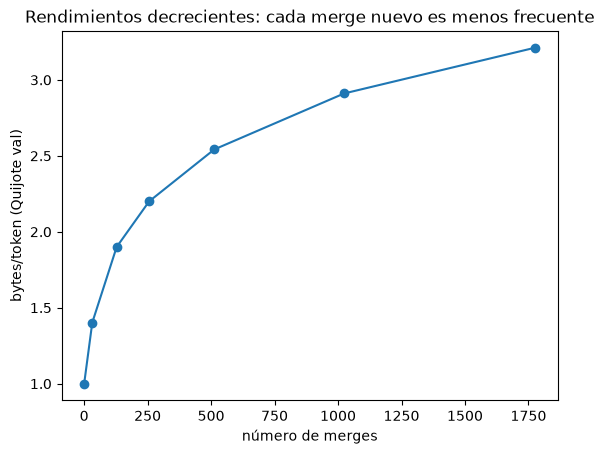


split del prompt fijo: ['En', ' un', ' lugar', ' de', ' la', ' Mancha']
últimos merges: [' desgracia', 'aun', ' dere', 'alle', 'uir', 'uió', 'ienen', ' hago', ' tenga', ' fuere', ' mercedes', ' menti']


In [7]:
import time

split_at = int(0.9 * len(quijote))
q_train, q_val = quijote[:split_at], quijote[split_at:]
start = time.perf_counter()
q_tok = BPETokenizer.train(count_chunks([q_train]), vocab_size=2048)
print(f"entrenado en {time.perf_counter() - start:.1f}s")

val_bytes = len(q_val.encode("utf-8"))
ks = [0, 32, 128, 256, 512, 1024, len(q_tok.merges)]
ratios = [val_bytes / len(BPETokenizer(q_tok.merges[:k]).encode(q_val)) for k in ks]
for k, r in zip(ks, ratios):
    print(f"{k:5d} merges -> {r:.2f} bytes/token")

plt.plot(ks, ratios, marker="o")
plt.xlabel("número de merges")
plt.ylabel("bytes/token (Quijote val)")
plt.title("Rendimientos decrecientes: cada merge nuevo es menos frecuente")
plt.show()

print("\nsplit del prompt fijo:", [q_tok.decode([i]) for i in q_tok.encode("En un lugar de la Mancha")])
print("últimos merges:", [q_tok.decode([256 + i]) for i in range(len(q_tok.merges) - 12, len(q_tok.merges))])

## 6. Tokens especiales

`<|user|>`, `<|assistant|>`, `<|tool_call|>`... tienen ids propios al final del vocabulario. Por defecto `encode` los trata como texto normal, para que un documento de internet no pueda inyectar tokens de control. Solo el código del chat template (fase 5) usará `allow_special=True`.

In [8]:
chat = "<|user|>¿Qué hora es?<|end|><|assistant|>"
print("allow_special=True :", q_tok.encode(chat, allow_special=True))
print("allow_special=False:", q_tok.encode(chat)[:12], "...  (texto normal)")
print("ids especiales:", {t: i for t, i in list(q_tok.special_tokens.items())[:5]})

allow_special=True : [2034, 1959, 1224, 1558, 288, 63, 2036, 2035]
allow_special=False: [60, 124, 372, 265, 124, 62, 1959, 1224, 1558, 288, 63, 60] ...  (texto normal)
ids especiales: {'<|endoftext|>': 2032, '<|system|>': 2033, '<|user|>': 2034, '<|assistant|>': 2035, '<|end|>': 2036}


## 7. De loss por token a bits por byte

Un token BPE contiene varios bytes, así que predecirlo es más difícil y la loss por token **sube** aunque el modelo sea mejor. Para comparar tokenizers distintos se reparte la información total entre los bytes:

`bits/byte = loss_por_token · n_tokens / (n_bytes · ln 2)`

Ejemplo con el bigrama de la fase 0 (3,327 bits/char en el val del Quijote):

In [9]:
n_chars, n_bytes = len(q_val), len(q_val.encode("utf-8"))
bits_per_char = 3.327
print(f"Quijote val: {n_chars:,} chars, {n_bytes:,} bytes -> {n_bytes / n_chars:.3f} bytes/char")
print(f"bigrama: {bits_per_char} bits/char = {bits_per_char * n_chars / n_bytes:.3f} bits/byte")

n_tokens = len(q_tok.encode(q_val))
print(f"\nCon este BPE, el mismo texto son {n_tokens:,} tokens ({n_bytes / n_tokens:.2f} bytes/token).")
print(f"Igualar al bigrama exigiría una loss de {bits_per_char * n_chars / n_tokens * math.log(2):.2f} nats/token.")

Quijote val: 211,071 chars, 217,025 bytes -> 1.028 bytes/char
bigrama: 3.327 bits/char = 3.236 bits/byte

Con este BPE, el mismo texto son 67,567 tokens (3.21 bytes/token).
Igualar al bigrama exigiría una loss de 7.20 nats/token.


## 8. Tokens en disco: `np.memmap`

`encode.py` escribe los ids como uint16 (2 bytes por token, vocabulario < 65.536) en un fichero plano. `np.memmap` lo abre **sin leerlo**: el sistema operativo carga solo las páginas que se tocan. Así se entrena con miles de millones de tokens en 16 GB de RAM.

In [10]:
import tempfile

ids = np.array(q_tok.encode(q_val), dtype=np.uint16)
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "val.bin"
    ids.tofile(path)
    tokens = np.memmap(path, dtype=np.uint16, mode="r")
    print(f"{path.stat().st_size:,} bytes en disco = {len(tokens):,} tokens × 2")
    i = 5000
    window = tokens[i : i + 20].tolist()  # random access, like get_batch will do in phase 3+
    print("ventana:", window)
    print("texto:  ", repr(q_tok.decode(window)))
    del tokens

135,134 bytes en disco = 67,567 tokens × 2
ventana: [1856, 553, 290, 385, 2022, 333, 10, 1240, 520, 430, 997, 261, 772, 275, 737, 274, 97, 396, 355, 578]
texto:   'ál era el más derecho\ncamino para ir a Barcelona sin tocar'


## 9. El tokenizer real de Leon

Si ya ejecutaste `train_tokenizer.py`, compara este tokenizer de juguete con el de verdad: 16.384 tokens entrenados con 100M de caracteres de Wikipedia.

In [11]:
leon_path = ROOT / "data" / "tokenizer" / "leon_bpe.json"
if leon_path.exists():
    leon = BPETokenizer.load(leon_path)
    for s in ["En un lugar de la Mancha", "La inteligencia artificial generativa", "¿Cuánto es 1234 * 5678?"]:
        print(f"{len(leon.encode(s)):2d} tokens:", [leon.decode([i]) for i in leon.encode(s)])
    print(f"\nQuijote val: {n_bytes / len(leon.encode(q_val)):.2f} bytes/token (juguete: {n_bytes / n_tokens:.2f})")
else:
    print("Ejecuta: python phases/2_tokenizer/train_tokenizer.py")

 6 tokens: ['En', ' un', ' lugar', ' de', ' la', ' Mancha']
 5 tokens: ['La', ' inteligencia', ' artificial', ' genera', 'tiva']
12 tokens: ['¿', 'Cu', 'án', 'to', ' es', ' 123', '4', ' *', ' 56', '7', '8', '?']



Quijote val: 3.50 bytes/token (juguete: 3.21)
